In [1]:
import numpy as np
import pandas as pd
import torch
import h5py
import joblib
import os, sys
import subprocess
import matplotlib.pyplot as plt
import math, json

In [2]:
import sys
sys.path.insert(0, "/mnt/efsUCE/umap_pytorch")  #git+https://github.com/ucscBrainExplorer/umap_pytorch.git
import umap_pytorch
print(umap_pytorch.__file__)

/mnt/efsUCE/umap_pytorch/umap_pytorch/__init__.py


In [3]:
results_dir = "/mnt/efsUCE/Bhaduri-NatNeurosci-2025_shuffled/"

embedding_h5_file = "pca.h5"
embedding_h5_file_key = "pca"
knn_outfile = "knn_30_ivfflat.npz"
k = 10
batch_size= 2048 #1024 #512, #256, #64, # gpu memory related

existing_model_iteration = 5
epochs = 5

## Load Embedding back into memory

In [4]:
# Load the embedding data
# Open the HDF5 file
with h5py.File(os.path.join(results_dir, embedding_h5_file), "r") as f:
    X_data = f[embedding_h5_file_key][:]

# Convert to PyTorch tensor so to use gpu
data_tensor = torch.from_numpy(X_data)
data_tensor, data_tensor.shape

(tensor([[ 0.3865, -0.2251,  0.1194,  ..., -0.0011, -0.0322,  0.0337],
         [-0.4470,  0.1744,  0.1190,  ..., -0.0234,  0.0154,  0.0156],
         [ 0.0779,  0.1411, -0.0919,  ..., -0.0073, -0.0243, -0.0469],
         ...,
         [-0.1074,  0.1231,  0.1946,  ...,  0.0455, -0.0145,  0.0269],
         [-0.1261, -0.0575, -0.5045,  ...,  0.0480,  0.0283,  0.0053],
         [ 0.0125,  0.2715,  0.0704,  ..., -0.0292, -0.0127, -0.0173]]),
 torch.Size([599211, 50]))

## Load Knn Back

In [5]:
# load knn back
data = np.load(os.path.join(results_dir, knn_outfile))
knn_indices = data["indices"]
knn_distances = data["distances"]

In [6]:
knn_distances = np.sqrt(knn_distances)

## PUMAP 
using umap_pytorch https://github.com/ucscBrainExplorer/umap_pytorch.git

## set up training on all cells

In [11]:
knn_indices = knn_indices[:,:k]
knn_dists = knn_distances[:,:k]

### Load model back or start with a new model

In [7]:
if existing_model_iteration > 0:
    from umap_pytorch import load_pumap
    path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
    pumap = load_pumap(path)
    pumap.epochs = epochs
    print ("Start with existing model", f'pytorch_e{existing_model_iteration}.pkl')
else:
    import torch.nn.functional as F
    pumap = umap_pytorch.PUMAP(
        encoder=None,           # nn.Module, None for default
        decoder=None,           # nn.Module, True for default, None for encoder only
        n_neighbors=10,
        min_dist= 0.1,
        metric="euclidean",
        n_components=2,
        beta=1.0,               # How much to weigh reconstruction loss for decoder
        reconstruction_loss=F.binary_cross_entropy_with_logits, # pass in custom reconstruction loss functions
        random_state=None,
        lr=1e-3,
        epochs=epochs, #5,
        batch_size= batch_size,
        num_workers=0, #10,
        num_gpus=1,
        match_nonparametric_umap=False, # Train network to match embeddings from non parametric umap,
    )
    print ("Start with a new model")

Loading PUMAP object from pickled file.
Start with existing model pytorch_e5.pkl


### Train

In [13]:
existing_model_iteration, pumap.epochs

(0, 5)

In [14]:
np.product = np.prod  # alias to fix compatibility
pumap.fit(data_tensor, knn_indices, knn_dists)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/home/ec2-user/.local/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default


Fitting parametric Umap
There are knn provided by the user
Start fuzzy_simplicial_set ...
End fuzzy_simplicial_set
Training start
Start UMAPDataset initiation ...
batch_size: 2048
End UMAPDataset. 757796736 599211


/mnt/efsUCE/umap_pytorch/umap_pytorch/data.py:37: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.data = torch.tensor(data, device="cuda")
You are using a CUDA device ('NVIDIA L4') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type            | Params | Mode 
----------------------------------------------------
0 | encoder | default_encoder | 91.0 K | train
----------------------------------------------------
91.0 K    Trainable params
0         Non-trainable params
91.0 K    Total params
0.364     Total estimated model 

dataloader len: 292


/home/ec2-user/.local/lib/python3.9/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Training: |                                                                                                   …

`Trainer.fit` stopped: `max_epochs=5` reached.


### Saving model

In [15]:
existing_model_iteration = existing_model_iteration+ pumap.epochs
existing_model_iteration

5

In [7]:
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
pumap.save(model_path)

NameError: name 'pumap' is not defined

### Quick viz X_umap_pytorch

In [8]:
# load model
from umap_pytorch import load_pumap
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
pumap = load_pumap(model_path)
print("Loaded model", f'pytorch_e{existing_model_iteration}.pkl')

Loading PUMAP object from pickled file.
Loaded model pytorch_e5.pkl


#### random 500K

In [9]:
view_size = 500_000
if X_data.shape[0] < view_size:
    subset_indices = range (0, X_data.shape[0])
else:
    np.random.seed(42)  # set seed for reproducibility
    subset_indices = np.random.choice(X_data.shape[0], size= view_size, replace=False)

In [10]:
X_umap_pytorch = pumap.transform(data_tensor[subset_indices])

Reducing array of shape torch.Size([500000, 50]) to (500000, 2)


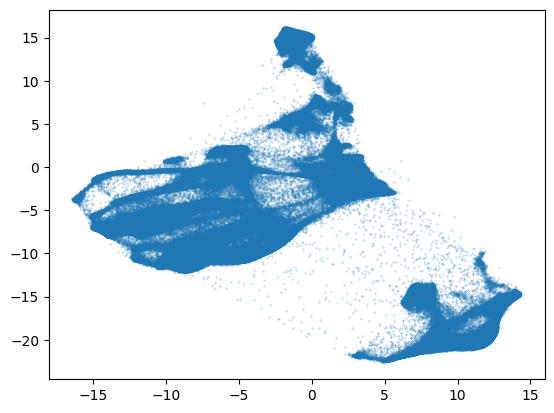

In [11]:
# current
plt.scatter(X_umap_pytorch[:,0], X_umap_pytorch[:,1], alpha =0.5, s=0.1)
plt.show()

## optional quick viz with metadata

In [12]:
metadata_file = "obs.tsv.gz"
metadata = pd.read_csv(os.path.join(results_dir, metadata_file), sep ='\t')

/tmp/ipykernel_6967/1713414368.py:2: DtypeWarning: Columns (242) have mixed types. Specify dtype option on import or set low_memory=False.
  metadata = pd.read_csv(os.path.join(results_dir, metadata_file), sep ='\t')


In [13]:
metadata.columns

Index(['Unnamed: 0', 'old_index', 'Class', 'Dataset', 'Dev_Period_Kang2011',
       'Gestational_week', 'Indvd', 'Indvd_Cluster_ID', 'State', 'Subtype.v1',
       ...
       'module_99', 'nCount_RNA', 'nFeature_RNA', 'orig.ident',
       'recombined_clusters', 'dataset_id', 'n_genes', 'collection_doi',
       'collection_doi_label', 'dataset_title'],
      dtype='object', length=248)

In [14]:
metadata["Type.v2"].value_counts()

Type.v2
Excitatory Neuron    237352
Inhibitory Neuron    124268
Newborn Neuron        75633
RG                    51114
Div                   33467
IPC                   29233
OPC                   15767
Microglia             11309
RG.div                 7976
Astrocyte              3997
Endothelial            2921
Oligodendrocyte        2900
OPC.div                1399
Pericyte               1273
Red blood cells         297
Name: count, dtype: int64

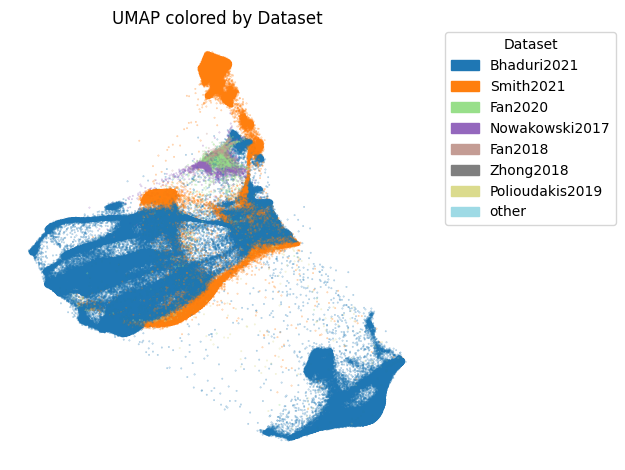

In [15]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize

metadata_feature = "Dataset"

colors = metadata[metadata_feature].iloc[subset_indices]

# only top category are plotted, ordered by frequency
top_cats = colors.value_counts().nlargest(20).index  # frequency order
colors = colors.where(colors.isin(top_cats), other="other")

# use frequency order (not alphabetical) so legend matches value_counts rank
unique_cats = list(top_cats) + ["other"]
cat_to_code = {cat: i for i, cat in enumerate(unique_cats)}
category_codes = colors.map(cat_to_code)

cmap = plt.get_cmap('tab20')
norm = Normalize(vmin=0, vmax=len(unique_cats) - 1)

scatter = plt.scatter(X_umap_pytorch[:, 0], X_umap_pytorch[:, 1],
                    c=category_codes, alpha=0.5, s=0.1, cmap=cmap, norm=norm)

patches = [mpatches.Patch(color=cmap(norm(i)), label=cat)
         for i, cat in enumerate(unique_cats)]
plt.legend(handles=patches, markerscale=5, title=metadata_feature,
         bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.axis('off')
plt.title(f"UMAP colored by {metadata_feature}")
plt.tight_layout()
plt.show()

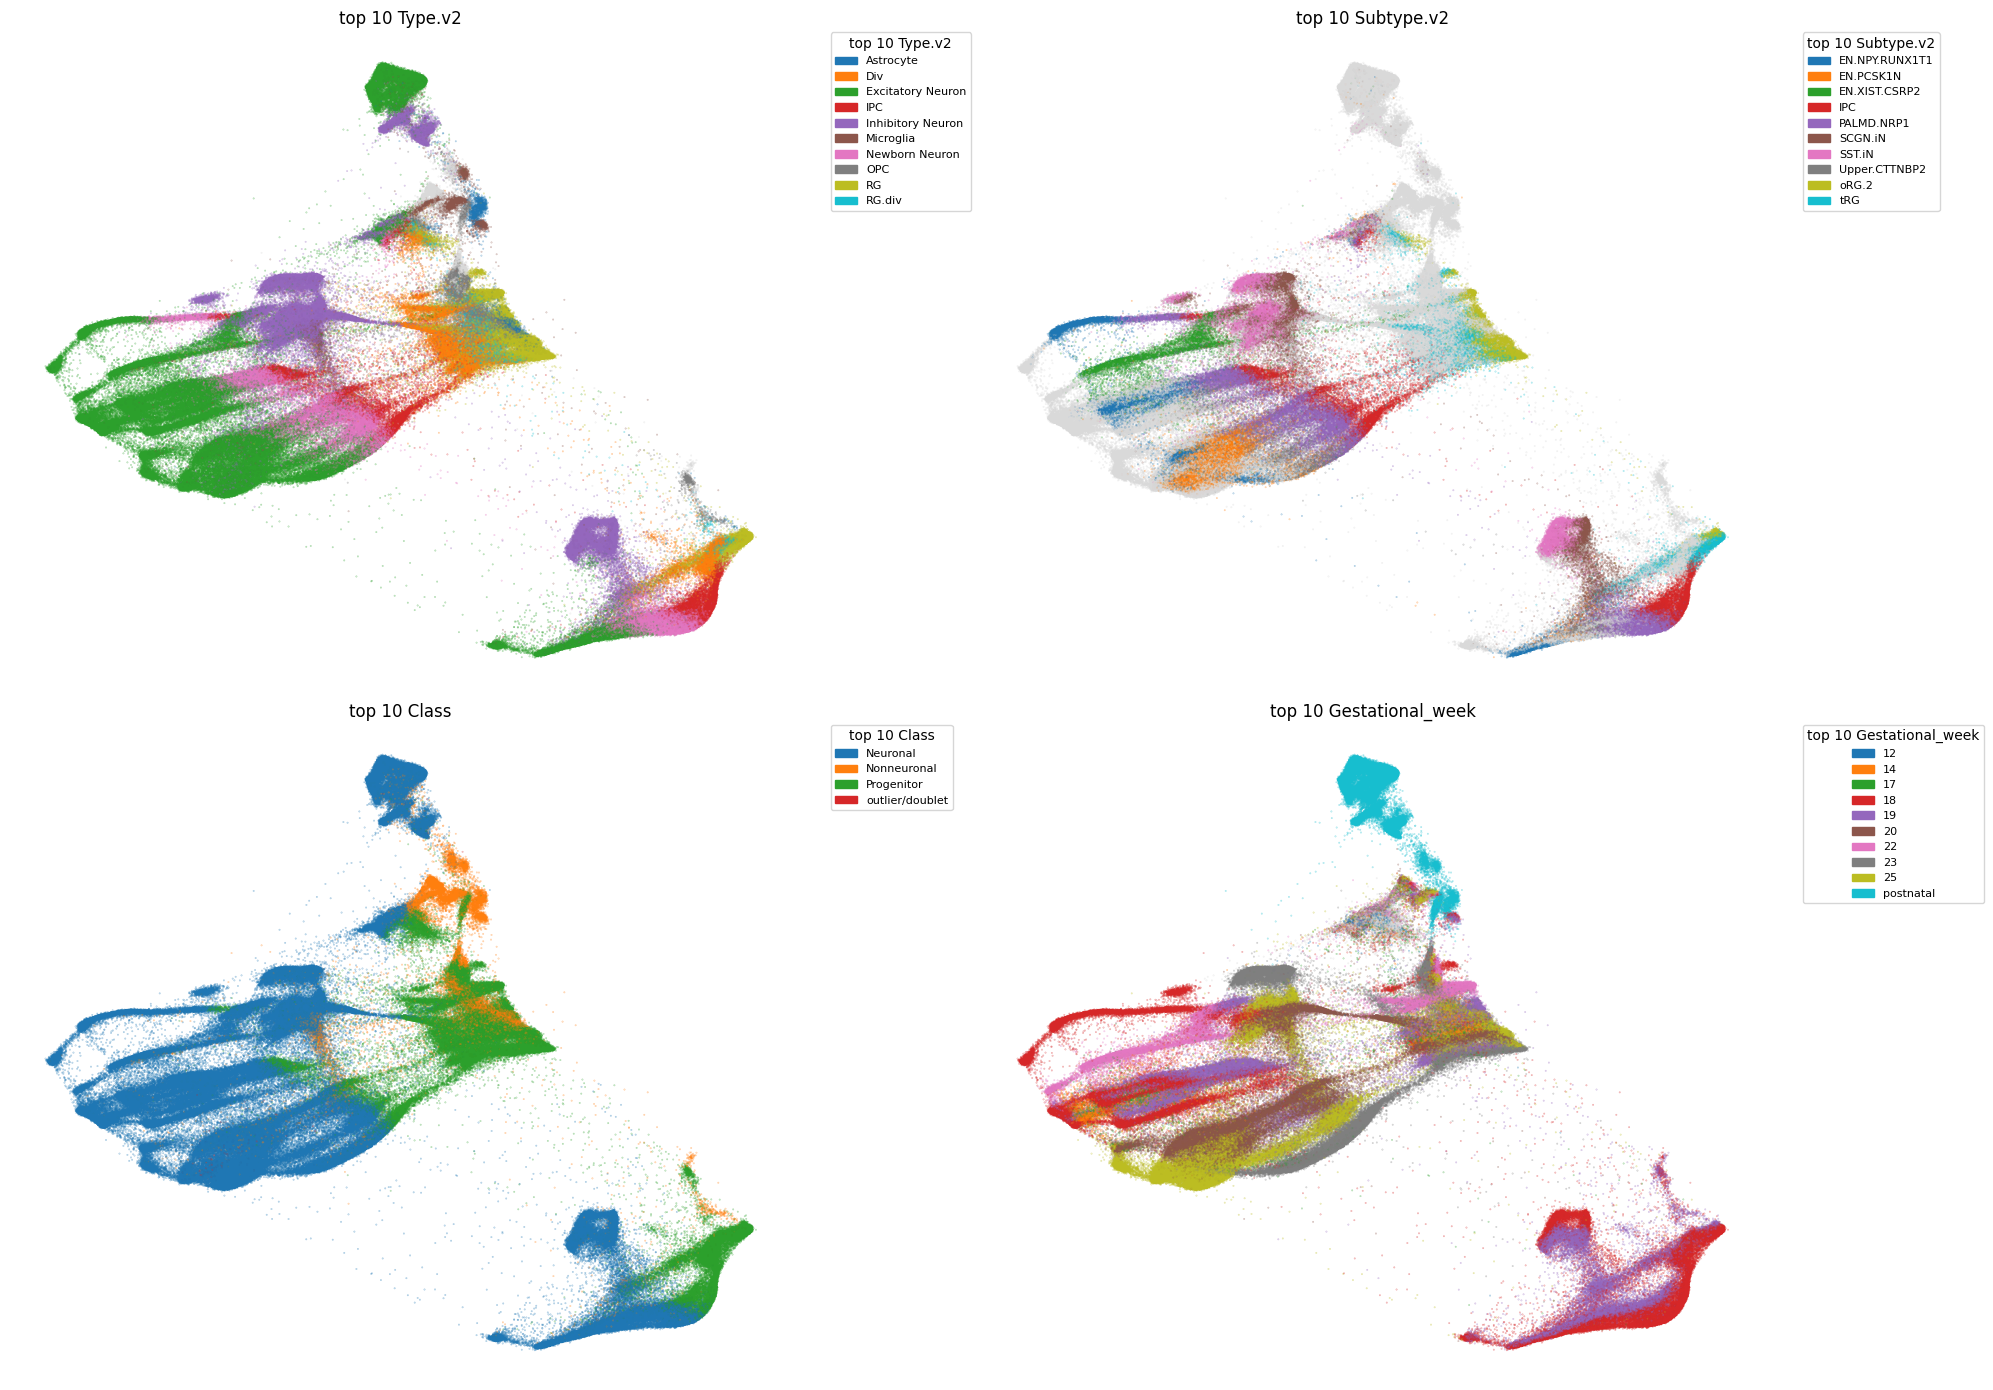

In [16]:
import matplotlib.pyplot as plt                                                                                                                                                                           
import matplotlib.patches as mpatches  
                                                                                                                                                                                                        
features = ["Type.v2", "Subtype.v2","Class", "Gestational_week"]                                                                                                                                                   
top_n = 10                                                                                                                                                                                                
                                                    
fig, axes = plt.subplots(2, 2, figsize=(20, 14))                                                                                                                                                          
axes = axes.flatten()                                                                                                                                                           

for ax, metadata_feature in zip(axes, features):                                                                                                                                                          
  colors = metadata[metadata_feature].iloc[subset_indices]
  top_cats = colors.value_counts().nlargest(top_n).index
  labels = colors.where(colors.isin(top_cats), other="other")                                                                                                                                           
  unique_cats = [c for c in labels.astype('category').cat.categories if c != "other"]
                                                                                                                                                                                                        
  cmap = plt.get_cmap('tab10')                          
  color_map = {cat: cmap(i / top_n) for i, cat in enumerate(unique_cats)}                                                                                                                               
  color_map["other"] = (0.85, 0.85, 0.85, 0.3)          
  point_colors = labels.map(color_map)                                                                                                                                                                  

  ax.scatter(X_umap_pytorch[:, 0], X_umap_pytorch[:, 1],                                                                                                                                                
             c=point_colors, alpha=0.5, s=0.1)          
                                                                                                                                                                                                        
  patches = [mpatches.Patch(color=color_map[cat], label=cat) for cat in unique_cats]
  ax.legend(handles=patches, markerscale=5, title=f"top {top_n} {metadata_feature}",                                                                                                                    
            bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0, fontsize=8)                                                                                                                    
  ax.axis('off')
  ax.set_title(f"top {top_n} {metadata_feature}")                                                                                                                                                       
                                                                                                                                                                                                        
plt.tight_layout()
plt.show()   

## Save UMAP

In [117]:
n_samples = data_tensor.shape[0]
embedding_dim = 2  # since n_components=2
X_umap_pytorch = np.zeros((n_samples, embedding_dim), dtype=np.float32)

# --- Batch transform ---
print("Starting batch transformation ...", flush=True)
batch_size = 1_000_000
for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)
    batch = data_tensor[start:end]
    emb = pumap.transform(batch)
    X_umap_pytorch[start:end] = emb
    print(f"Processed {end}/{n_samples}", flush=True)

Starting batch transformation ...
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 1000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 2000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 3000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 4000000/5622490
Reducing array of shape torch.Size([1000000, 50]) to (1000000, 2)
Processed 5000000/5622490
Reducing array of shape torch.Size([622490, 50]) to (622490, 2)
Processed 5622490/5622490


In [118]:
config = {}
model_path = os.path.join(results_dir, f'pytorch_e{existing_model_iteration}.pkl')
config["pumap_model_file"] = model_path
config["pca_model_file"]= os.path.join(results_dir,"ipca_model.pkl") # hard-coded for ipca transformation
config["knn_k"] = 30
config["knn_nprobe"] = 20
config["pca_n_components"] =50

# --- Axis adjustment ---
UMAP1_size = np.ptp(X_umap_pytorch[:, 0])
UMAP2_size = np.ptp(X_umap_pytorch[:, 1])
if UMAP1_size < UMAP2_size:
    print("Swapping axes (too tall UMAP)...", flush=True)
    X_umap_pytorch[:, [0, 1]] = X_umap_pytorch[:, [1, 0]]
    config["swap_xy_matrix"] =  [
        [0, 1],
        [1, 0]
    ]
else:
    config["swap_xy_matrix"] =  [
        [1, 0],
        [0, 1]
    ]
config["PUMAP_k"]=k
config

Swapping axes (too tall UMAP)...


{'pumap_model_file': '/mnt/efsUCE/analysis/immune_atlas/data/combined_4layers_shuffled_v2/pytorch_e35.pkl',
 'pca_model_file': '/mnt/efsUCE/analysis/immune_atlas/data/combined_4layers_shuffled_v2/ipca_model.pkl',
 'knn_k': 30,
 'knn_nprobe': 20,
 'pca_n_components': 50,
 'swap_xy_matrix': [[0, 1], [1, 0]],
 'PUMAP_k': 10}

In [119]:
# --- Saveing transformation config ----
config_path = os.path.join(results_dir, f"transform_e{existing_model_iteration}.json")
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

In [120]:
# --- Save umap ----
umap_file = f"umap_e{existing_model_iteration}.npy"
output_path = os.path.join(results_dir, umap_file)
np.save(output_path, X_umap_pytorch)